In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Sequential

from tensorflow.keras.optimizers import Adam

In [2]:
DATA_PATH = r"C:/Users/Dell/Downloads/caltech-101/caltech-101/101_ObjectCategories/101_ObjectCategories"

print("Dataset path:", DATA_PATH)

Dataset path: C:/Users/Dell/Downloads/caltech-101/caltech-101/101_ObjectCategories/101_ObjectCategories


In [3]:
categories = [
    "airplanes",
    "butterfly",
    "chair",
    "elephant",
    "laptop"
]

print("Selected categories:")
print(categories)

Selected categories:
['airplanes', 'butterfly', 'chair', 'elephant', 'laptop']


In [4]:
datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    classes=categories,
    class_mode="categorical",
    batch_size=16,
    subset="training",
    shuffle=False
)

test_data = datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    classes=categories,
    class_mode="categorical",
    batch_size=16,
    subset="validation",
    shuffle=False
)

print("Training images:", train_data.samples)
print("Testing images:", test_data.samples)

Found 880 images belonging to 5 classes.
Found 218 images belonging to 5 classes.
Training images: 880
Testing images: 218


In [5]:
vgg16 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 loaded successfully")

VGG16 loaded successfully


In [6]:
vgg16.trainable = False

print("VGG16 layers are frozen")

VGG16 layers are frozen


In [7]:
feature_extractor = Sequential([
    vgg16,
    GlobalAveragePooling2D()
])

feature_extractor.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [8]:
train_features = feature_extractor.predict(
    train_data,
    verbose=1
)

train_labels = train_data.classes

print("Training features shape:", train_features.shape)

55/55 ━━━━━━━━━━━━━━━━━━━━ 288s 5s/step
Training features shape: (880, 512)


In [9]:
test_features = feature_extractor.predict(
    test_data,
    verbose=1
)
test_labels = test_data.classes

print("Testing features shape:", test_features.shape)

14/14 ━━━━━━━━━━━━━━━━━━━━ 71s 5s/step
Testing features shape: (218, 512)


In [10]:
num_classes = len(categories)
classifier = Sequential([
    Dense(128, activation="relu",
          input_shape=(train_features.shape[1],)),
    
    Dense(num_classes, activation="softmax")
])
classifier.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 66,309 (259.02 KB)

 Trainable params: 66,309 (259.02 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
Dense(5, activation="softmax")

<Dense name=dense_2, built=False>

In [12]:
classifier.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Classifier compiled successfully")

Classifier compiled successfully


In [13]:
history = classifier.fit(
    train_features,
    train_labels,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9446 - loss: 0.2480 - val_accuracy: 0.0455 - val_loss: 35.0628
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 1.0000 - loss: 1.6904e-04 - val_accuracy: 0.0511 - val_loss: 38.2604
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 1.0000 - loss: 3.1570e-05 - val_accuracy: 0.0511 - val_loss: 38.6908
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 1.0000 - loss: 2.4682e-05 - val_accuracy: 0.0511 - val_loss: 38.7407
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 1.0000 - loss: 2.2848e-05 - val_accuracy: 0.0511 - val_loss: 38.7604
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - loss: 2.1050e-05 - val_accuracy: 0.0511 - val_loss: 38.7659
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 1.0000 - loss: 1.9477e-05 - val_accuracy: 0.0511 - val_loss: 38.7639
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 1.0000 - loss: 1.

In [14]:
loss, accuracy = classifier.evaluate(
    test_features,
    test_labels
)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8119 - loss: 7.1358    
Test Accuracy: 0.8119266033172607
Test Accuracy (%): 81.19266033172607


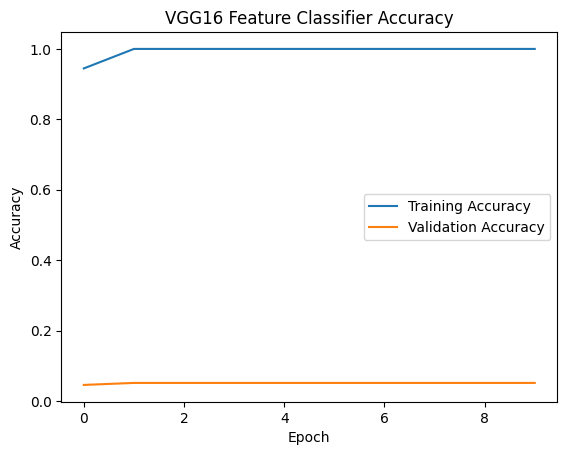

In [17]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG16 Feature Classifier Accuracy")

plt.legend()
plt.show()